# Setup

In [1]:
import pandas as pd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
all_counts = pd.read_csv("run_simulation/results/for_hier_norm/window_counts/window_counts.tsv",
                         sep = "\t")
skipper_finds = pd.read_csv("run_simulation/results/for_hier_norm/flipper/intermediates/window_counts_INw.tsv",
                     sep = "\t")
IP_counts = skipper_finds.merge(all_counts, how = "left")

# Helper functions

In [3]:
def apply_size_factors(df, size_factors):
    df_norm = df.copy()

    for col, sf in size_factors.items():
        if col in df_norm.columns:
            df_norm[col] = df_norm[col] / sf

    return df_norm

In [4]:
def plot_total_counts(summary, cols, output_file, bottom = 100, top = 100000000):

    x = np.arange(len(cols))
    width = 0.35

    # Custom labels.
    x_labels = ["Ctrl IP rep1","Ctrl IP rep2","Trt IP rep1","Trt IP rep2"]

    # Initialize plot.
    fig, ax = plt.subplots(figsize=(6, 3.5))

    # Add bar plots. 
    ax.bar(x - width/2,summary["All windows"],width,label="Background windows")
    ax.bar(x + width/2,summary["IP windows"],width,label="Binding windows")

    # Add custom ticks.
    ax.set_xticks(x)
    ax.set_xticklabels(x_labels,rotation=30,ha="right",fontsize=13)

    # logscale y values and zoom in on the important part of the graph. 
    ax.set_yscale("symlog", linthresh=1)
    ax.set_ylim(bottom=bottom, top=top)

    # Set cutom Y-labels. 
    ax.set_ylabel("Total counts (log scale)",fontsize=15)
    ax.tick_params(axis="y", labelsize=14)

    # Configure, save, and show the plot. 
    plt.tight_layout()
    plt.savefig(output_file,format="svg")
    plt.show()

# Data wrangling

In [5]:
# Load up the size factors
hier_df = pd.read_table("run_simulation/results/for_hier_norm/flipper/intermediates/normalization_factors.tsv")
backg_df = pd.read_table("run_simulation/results/for_hier_norm/flipper/intermediates/normalization_factors_backg.tsv")

# convert to dictionaries. 
sf_MOR_hier = dict(zip(hier_df["Sample"], hier_df["SizeFactor"]))
sf_MOR_backg = dict(zip(backg_df["Sample"], backg_df["SizeFactor"]))

# MOR_backg normalization
all_counts_MOR_backg = apply_size_factors(all_counts, sf_MOR_backg)
IP_counts_MOR_backg  = apply_size_factors(IP_counts,  sf_MOR_backg)

# MOR_hier normalization
all_counts_MOR_hier = apply_size_factors(all_counts, sf_MOR_hier)
IP_counts_MOR_hier  = apply_size_factors(IP_counts,  sf_MOR_hier)

In [6]:
cols = ["control_IP_1", "control_IP_2", "treatment_IP_1", "treatment_IP_2"]

# Sum counts per column.
all_totals = all_counts[cols].sum()
ip_totals  = IP_counts[cols].sum()

# Sum counts per column.
all_totals_MOR_backg = all_counts_MOR_backg[cols].sum()
ip_totals_MOR_backg  = IP_counts_MOR_backg[cols].sum()

# Sum counts per column.
all_totals_MOR_hier = all_counts_MOR_hier[cols].sum()
ip_totals_MOR_hier  = IP_counts_MOR_hier[cols].sum()

# Create summary table. 
summary = pd.DataFrame({"sample": cols, "All windows": all_totals.values, "IP windows": ip_totals.values})

summary_MOR_backg = pd.DataFrame({"sample": cols, "All windows": all_totals_MOR_backg.values, "IP windows": ip_totals_MOR_backg.values})

summary_MOR_hier = pd.DataFrame({"sample": cols, "All windows": all_totals_MOR_hier.values, "IP windows": ip_totals_MOR_hier.values})

# Plotting

## Raw

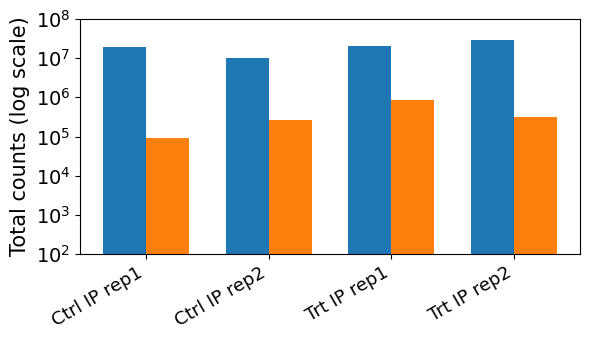

In [7]:
plot_total_counts(summary, cols, "total_ip_counts_raw.svg")

## MOR_backg

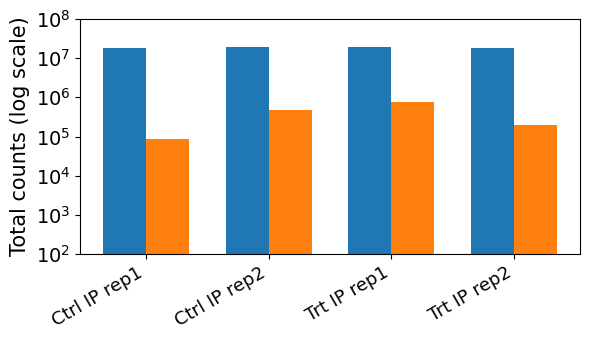

In [8]:
plot_total_counts(summary_MOR_backg, cols, "total_ip_counts_MOR_backg.svg")

## MOR_hier

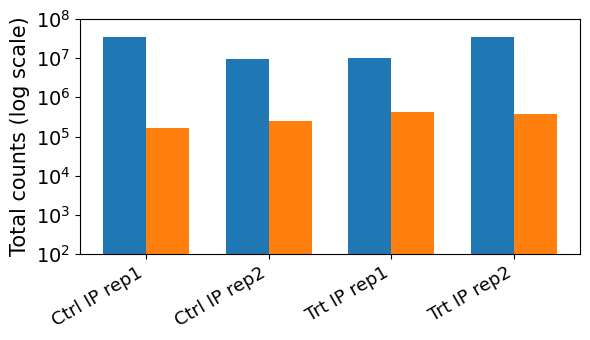

In [9]:
plot_total_counts(summary_MOR_hier, cols, "total_ip_counts_MOR_hier.svg")